In [ ]:
#load the dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
path = "/content/drive/MyDrive/CC GENERAL.csv"
df = pd.read_csv(path)
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [ ]:
print("dataset shape:",df.shape)
print("\nmissing values:",)
print(df.isnull().sum())
print("\nduplicate row:",df.duplicated().sum())
print("\nstatistical summary:")
display(df.describe().T)

dataset shape: (8950, 18)

missing values:
CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

duplicate row: 0

statistical summary:


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


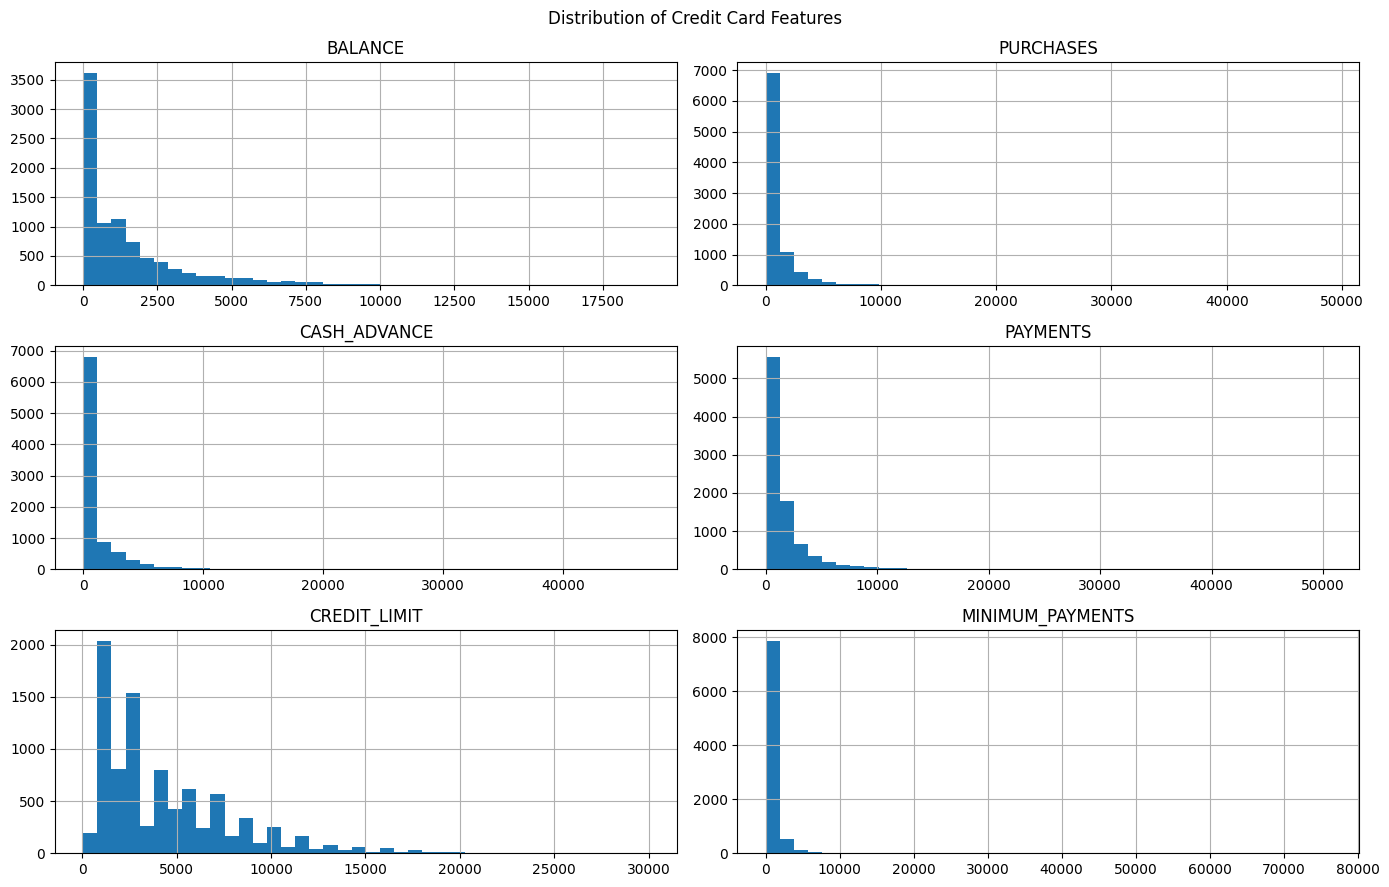

In [ ]:
#viualize the distribution
features = [ "BALANCE","PURCHASES","CASH_ADVANCE","PAYMENTS","CREDIT_LIMIT","MINIMUM_PAYMENTS"]
df[features].hist(figsize=(14, 9), bins=40)
plt.suptitle("Distribution of Credit Card Features")
plt.tight_layout()
plt.show()

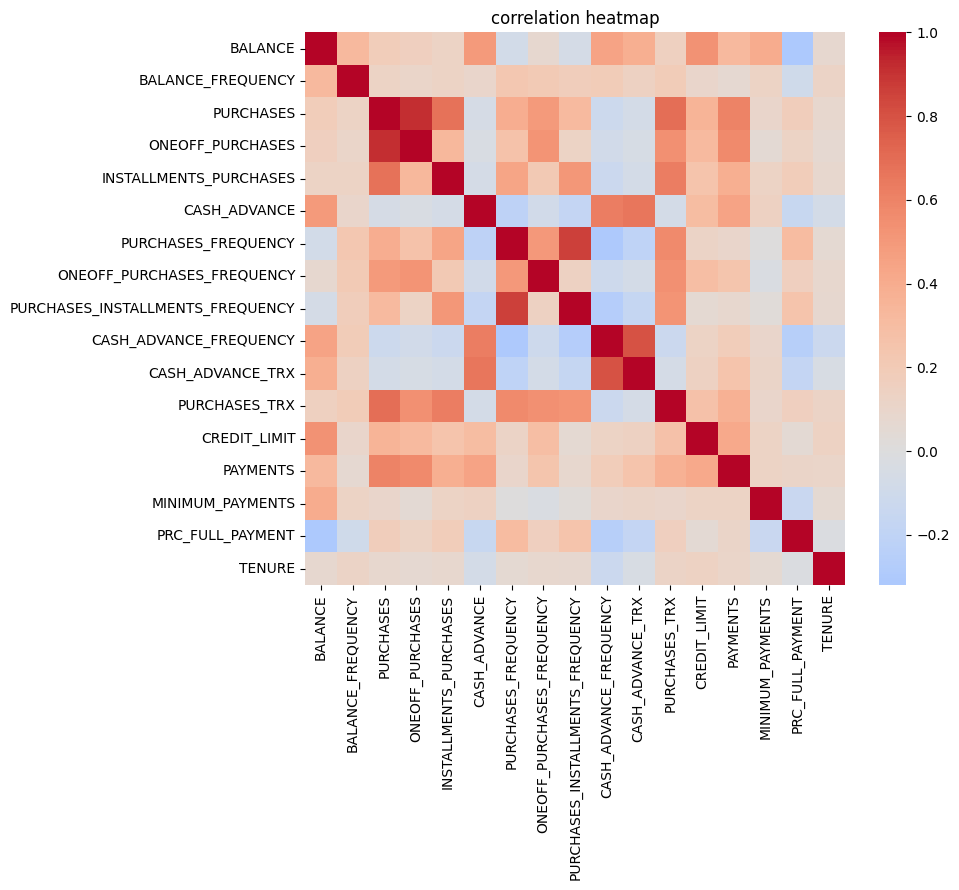

In [ ]:
#corelation and examiniation using the heap map
plt.figure(figsize=(10,9))
corr = df.drop(columns=["CUST_ID"]).corr()
sns.heatmap(corr,cmap="coolwarm",center=0,annot=False)
plt.title("correlation heatmap")
plt.tight_layout()
plt.show()

In [ ]:
# Show the strongest feature correlations
corr = df.drop(columns=["CUST_ID"]).corr()

corr_pairs = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
).stack()

display(
    corr_pairs.reindex(
        corr_pairs.abs().sort_values(ascending=False).index
    ).head(15).to_frame("Correlation")
)

Correlation
PURCHASES                        ONEOFF_PURCHASES                     0.916845
PURCHASES_FREQUENCY              PURCHASES_INSTALLMENTS_FREQUENCY     0.862934
CASH_ADVANCE_FREQUENCY           CASH_ADVANCE_TRX                     0.799561
PURCHASES                        PURCHASES_TRX                        0.689561
                                 INSTALLMENTS_PURCHASES               0.679896
CASH_ADVANCE                     CASH_ADVANCE_TRX                     0.656498
                                 CASH_ADVANCE_FREQUENCY               0.628522
INSTALLMENTS_PURCHASES           PURCHASES_TRX                        0.628108
PURCHASES                        PAYMENTS                             0.603264
PURCHASES_FREQUENCY              PURCHASES_TRX                        0.568430
ONEOFF_PURCHASES                 PAYMENTS                             0.567292
                                 PURCHASES_TRX                        0.545523
ONEOFF_PURCHASES_FREQUENCY       PURCHASES_TRX                        0.544869
BALANCE                          CREDIT_LIMIT                         0.531283
PURCHASES_INSTALLMENTS_FREQUENCY PURCHASES_TRX                        0.529975

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Remove customer ID
X = df.drop(columns=["CUST_ID"]).copy()

# 2. Handle missing values
imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# 3. Version A: StandardScaler only
scaler_a = StandardScaler()

X_a = pd.DataFrame(
    scaler_a.fit_transform(X_imputed),
    columns=X_imputed.columns,
    index=X_imputed.index
)

# 4. Version B: log transformation + StandardScaler
log_features = [
    "BALANCE",
    "PURCHASES",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE",
    "CREDIT_LIMIT",
    "PAYMENTS",
    "MINIMUM_PAYMENTS"
]

X_log = X_imputed.copy()
X_log[log_features] = np.log1p(X_log[log_features])

scaler_b = StandardScaler()

X_b = pd.DataFrame(
    scaler_b.fit_transform(X_log),
    columns=X_log.columns,
    index=X_log.index
)

print("Version A shape:", X_a.shape)
print("Version B shape:", X_b.shape)
print("Missing values in Version A:", X_a.isnull().sum().sum())
print("Missing values in Version B:", X_b.isnull().sum().sum())

Version A shape: (8950, 17)
Version B shape: (8950, 17)
Missing values in Version A: 0
Missing values in Version B: 0


In [ ]:
results_a = evaluate_kmeans(X_a, "StandardScaler")
results_b = evaluate_kmeans(X_b, "Log + StandardScaler")

results = pd.concat(
    [results_a, results_b],
    ignore_index=True
)

display(results.round(4))

,Version,K,Inertia,Silhouette,Davies_Bouldin
0,StandardScaler,2,127784.5345,0.2157,1.9120
1,StandardScaler,3,111975.0436,0.2403,1.5920
2,StandardScaler,4,99061.9398,0.2004,1.5748
3,StandardScaler,5,91490.4980,0.1975,1.5492
4,StandardScaler,6,84826.5920,0.2054,1.5064
5,StandardScaler,7,79856.1570,0.2108,1.4918
6,StandardScaler,8,74484.8801,0.2252,1.3697
7,Log + StandardScaler,2,119113.5113,0.2163,1.6711
8,Log + StandardScaler,3,101330.4536,0.2111,1.7115
9,Log + StandardScaler,4,92131.3286,0.2095,1.7052


In [ ]:
#Examine cluster sizes and customer profiles
from sklearn.cluster import KMeans

# Features for interpreting customer profiles
profile_features = [
    "BALANCE",
    "PURCHASES",
    "CASH_ADVANCE",
    "CREDIT_LIMIT",
    "PAYMENTS",
    "PURCHASES_FREQUENCY",
    "PRC_FULL_PAYMENT",
    "PURCHASES_TRX"
]

candidate_models = {}
candidate_labels = {}
candidate_profiles = {}

for k in [3, 8]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_a)

    candidate_models[k] = model
    candidate_labels[k] = labels

    # Cluster sizes
    sizes = pd.Series(labels).value_counts().sort_index()

    print(f"\nK = {k}: Cluster sizes")
    print(
        pd.DataFrame({
            "Customers": sizes,
            "Percentage": (sizes / len(df) * 100).round(2)
        })
    )

    # Profile customers in the original feature units
    profile_data = df[profile_features].copy()
    profile_data["Cluster"] = labels

    profile = profile_data.groupby("Cluster").median().round(2)
    candidate_profiles[k] = profile

    print(f"\nK = {k}: Median customer profiles")
    display(profile)


K = 3: Cluster sizes
   Customers  Percentage
0       1275       14.25
1       6114       68.31
2       1561       17.44

K = 3: Median customer profiles


,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PURCHASES_FREQUENCY,PRC_FULL_PAYMENT,PURCHASES_TRX
Cluster,,,,,,,,
0,1193.71,3055.87,0.00,7000.0,2689.04,1.00,0.08,44.0
1,432.97,299.95,0.00,2500.0,567.73,0.42,0.00,6.0
2,3508.56,0.00,3135.11,6000.0,1654.93,0.00,0.00,0.0



K = 8: Cluster sizes
   Customers  Percentage
0        897       10.02
1       2740       30.61
2       2005       22.40
3       1116       12.47
4       1179       13.17
5        364        4.07
6        624        6.97
7         25        0.28

K = 8: Median customer profiles


,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PURCHASES_FREQUENCY,PRC_FULL_PAYMENT,PURCHASES_TRX
Cluster,,,,,,,,
0,4804.07,107.33,4195.10,8000.0,2249.61,0.08,0.00,1.0
1,1250.64,45.74,290.17,2500.0,634.78,0.08,0.00,1.0
2,287.88,666.60,0.00,2500.0,772.32,1.00,0.00,14.0
3,624.97,1912.60,0.00,6000.0,1721.49,1.00,0.08,26.0
4,23.65,167.22,0.00,3000.0,415.60,0.18,0.00,3.0
5,2901.33,5543.16,0.00,8500.0,4868.56,1.00,0.00,82.0
6,506.77,168.61,470.67,1500.0,290.03,0.33,0.00,3.0
7,3454.09,25615.07,0.00,17000.0,26557.10,1.00,0.42,101.0


In [ ]:
#inspect the 25 customers in the cluster 7
# Inspect the small cluster from the K=8 model
df_k8 = df.copy()
df_k8["Cluster"] = candidate_labels[8]

cluster_7 = df_k8[df_k8["Cluster"] == 7]

print("Cluster 7 size:", len(cluster_7))

display(
    cluster_7[
        [
            "BALANCE",
            "PURCHASES",
            "CASH_ADVANCE",
            "CREDIT_LIMIT",
            "PAYMENTS",
            "PURCHASES_FREQUENCY",
            "PURCHASES_TRX"
        ]
    ].describe().T
)

Cluster 7 size: 25


,count,mean,std,min,25%,50%,75%,max
BALANCE,25.0,5351.546106,4235.586482,1268.809031,2774.249582,3454.094319,6372.182817,19043.13856
PURCHASES,25.0,27085.309200,8459.048271,12551.950000,22009.920000,25615.070000,31299.350000,49039.57000
CASH_ADVANCE,25.0,1488.363253,4791.367812,0.000000,0.000000,0.000000,0.000000,19513.47483
CREDIT_LIMIT,25.0,16360.000000,5626.425745,7500.000000,12000.000000,17000.000000,18000.000000,30000.00000
PAYMENTS,25.0,27159.043527,9708.374234,8760.860264,22350.292470,26557.097240,31698.419020,50721.48336
PURCHASES_FREQUENCY,25.0,0.892667,0.233833,0.166667,1.000000,1.000000,1.000000,1.00000
PURCHASES_TRX,25.0,123.320000,89.027018,3.000000,70.000000,101.000000,157.000000,358.00000


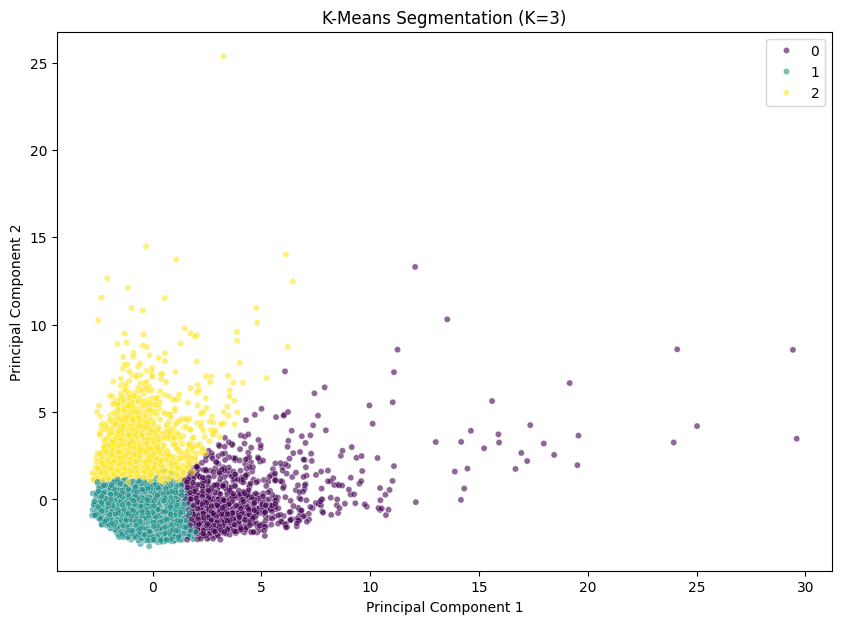

Variance explained: 47.61 %


In [ ]:
#PCA --> principal component analysis
#PCA visualization
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_a)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=candidate_labels[3],
    palette="viridis",
    alpha=0.6,
    s=20
)

plt.title("K-Means Segmentation (K=3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

print(
    "Variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [ ]:
#agglomerative clustering comparison
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import KMeans
import pandas as pd

comparison = []

for k in [3, 8]:

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    km_labels = km.fit_predict(X_a)

    agg = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    agg_labels = agg.fit_predict(X_a)

    for name, labels in [
        ("K-Means", km_labels),
        ("Agglomerative", agg_labels)
    ]:
        comparison.append({
            "Algorithm": name,
            "K": k,
            "Silhouette": silhouette_score(
                X_a, labels,
                sample_size=2000,
                random_state=42
            ),
            "Davies_Bouldin": davies_bouldin_score(
                X_a, labels
            ),
            "Smallest_cluster": pd.Series(labels).value_counts().min()
        })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))

,Algorithm,K,Silhouette,Davies_Bouldin,Smallest_cluster
0,K-Means,3,0.2403,1.5920,1275
1,Agglomerative,3,0.1548,1.8496,1194
2,K-Means,8,0.2252,1.3697,25
3,Agglomerative,8,0.1614,1.3882,23


In [ ]:
#check the cluster stability
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Baseline clustering
baseline = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
).fit_predict(X_a)

stability_results = []

# Compare multiple random seeds
for seed in [0, 10, 21, 42, 100]:

    labels = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=10
    ).fit_predict(X_a)

    stability_results.append({
        "Random_State": seed,
        "Adjusted_Rand_Index": adjusted_rand_score(
            baseline, labels
        )
    })

display(pd.DataFrame(stability_results).round(4))

,Random_State,Adjusted_Rand_Index
0,0,0.9723
1,10,0.9726
2,21,0.9726
3,42,1.0000
4,100,0.9726


In [ ]:
#save the final cluster result
# Fit the final model
final_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

final_labels = final_model.fit_predict(X_a)

# Save customer IDs and cluster assignments
final_results = pd.DataFrame({
    "CUST_ID": df["CUST_ID"],
    "Cluster": final_labels
})

final_results["Segment"] = final_results["Cluster"].map({
    0: "Frequent Higher-Spending Purchasers",
    1: "Lower-Activity Purchasers",
    2: "Cash-Advance-Oriented Customers"
})

final_results.to_csv(
    "credit_card_customer_segments.csv",
    index=False
)

print("Saved successfully!")
display(final_results.head())

Saved successfully!


,CUST_ID,Cluster,Segment
0,C10001,1,Lower-Activity Purchasers
1,C10002,2,Cash-Advance-Oriented Customers
2,C10003,1,Lower-Activity Purchasers
3,C10004,1,Lower-Activity Purchasers
4,C10005,1,Lower-Activity Purchasers


In [ ]:
# Count customers in each segment
segment_summary = (
    final_results
    .groupby(["Cluster", "Segment"])
    .size()
    .reset_index(name="Customer_Count")
)

segment_summary["Percentage"] = (
    segment_summary["Customer_Count"]
    / len(final_results) * 100
).round(2)

display(segment_summary)

,Cluster,Segment,Customer_Count,Percentage
0,0,Frequent Higher-Spending Purchasers,1275,14.25
1,1,Lower-Activity Purchasers,6114,68.31
2,2,Cash-Advance-Oriented Customers,1561,17.44


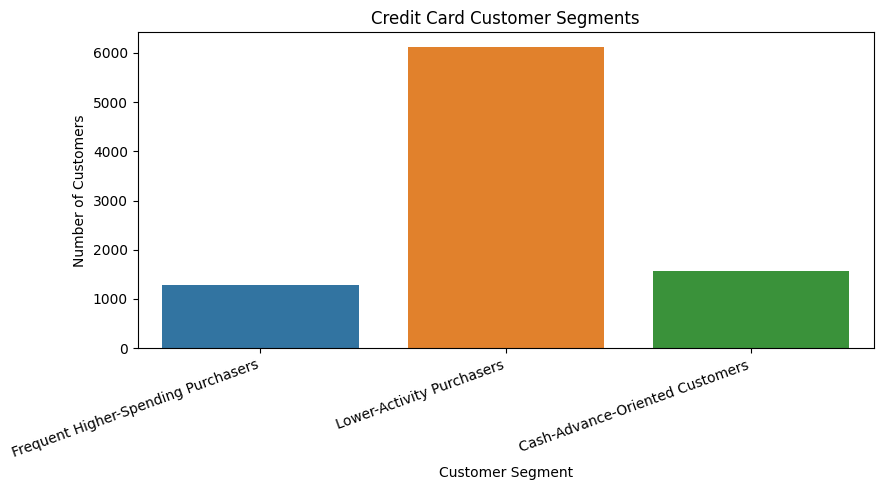

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Customer_Count",
    hue="Segment",
    legend=False
)

plt.title("Credit Card Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
profile_columns = [
    "BALANCE",
    "PURCHASES",
    "CASH_ADVANCE",
    "CREDIT_LIMIT",
    "PAYMENTS",
    "PURCHASES_FREQUENCY",
    "PRC_FULL_PAYMENT",
    "PURCHASES_TRX"
]

profile_df = df[profile_columns].copy()
profile_df["Cluster"] = final_labels

cluster_profile = (
    profile_df
    .groupby("Cluster")
    .median()
    .round(2)
)

display(cluster_profile)

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PURCHASES_FREQUENCY,PRC_FULL_PAYMENT,PURCHASES_TRX
Cluster,,,,,,,,
0,1193.71,3055.87,0.00,7000.0,2689.04,1.00,0.08,44.0
1,432.97,299.95,0.00,2500.0,567.73,0.42,0.00,6.0
2,3508.56,0.00,3135.11,6000.0,1654.93,0.00,0.00,0.0


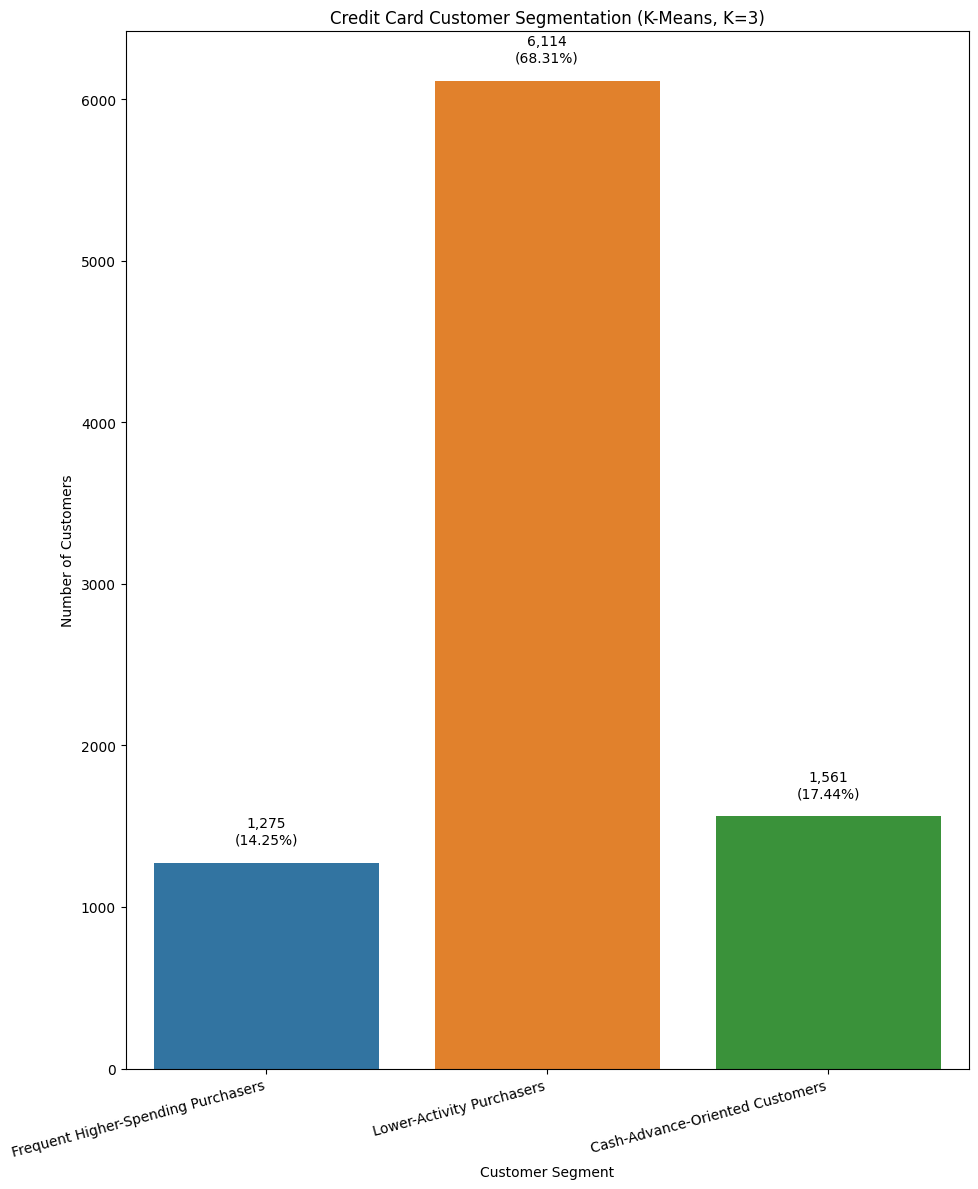

In [ ]:
plt.figure(figsize=(10,12))

ax = sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Customer_Count",
    hue="Segment",
    legend=False
)

for i, row in segment_summary.reset_index(drop=True).iterrows():
    ax.text(
        i,
        row["Customer_Count"] + 100,
        f'{row["Customer_Count"]:,}\n({row["Percentage"]:.2f}%)',
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Credit Card Customer Segmentation (K-Means, K=3)")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

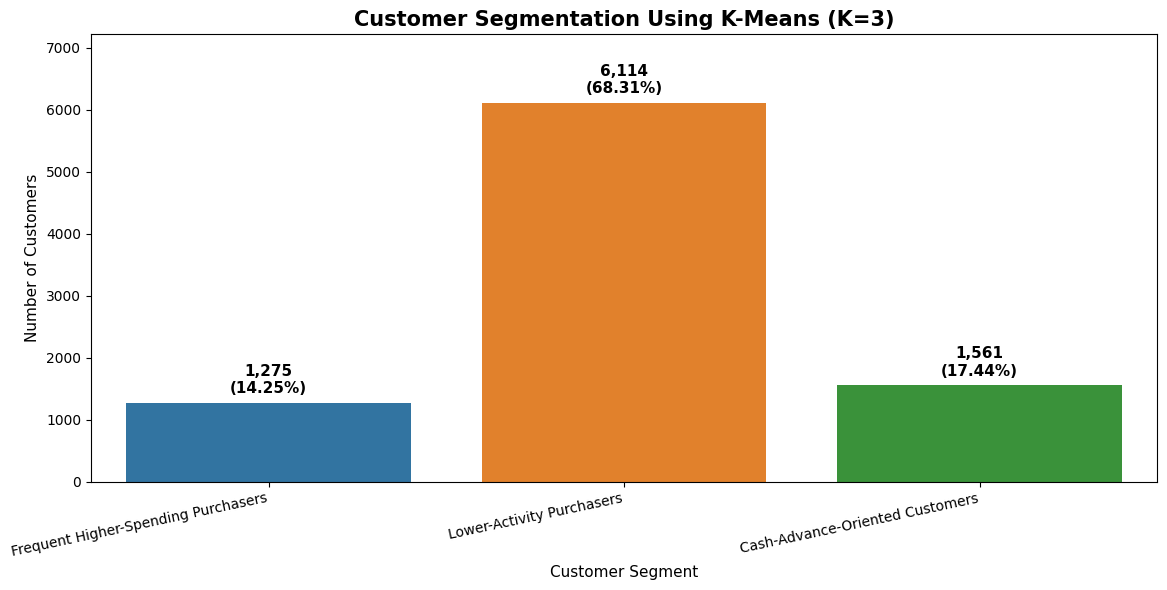

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Customer_Count",
    hue="Segment",
    legend=False
)

# Add customer count and percentage above each bar
for i, row in segment_summary.reset_index(drop=True).iterrows():
    ax.text(
        i,
        row["Customer_Count"] + 100,
        f'{row["Customer_Count"]:,}\n({row["Percentage"]:.2f}%)',
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Customer Segmentation Using K-Means (K=3)",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Customer Segment", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)
plt.xticks(rotation=12, ha="right")
plt.ylim(0, segment_summary["Customer_Count"].max() * 1.18)
plt.tight_layout()

# Save the chart for your project
plt.savefig(
    "customer_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()